# Exploratory Data Analysis: Student Academic Performance

**Dataset**: Combined UCI Student Performance (Mathematics + Portuguese)
**Source**: Cortez & Silva (2008) - Public secondary school data from Portugal
**Records**: 1,044 subject records
**Focus**: Relationship between study habits, absences, family factors and final grades (G3)

This notebook supports the Data Mining group project on Student Academic Performance.

The counts refer to subject records. The Mathematics and Portuguese files include some of the same students.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
%matplotlib inline

## 1. Load Data

In [4]:
# Load the cleaned dataset
import os
csv_path = 'student_performance_cleaned.csv'
if not os.path.exists(csv_path):
    # Try common alternative locations
    for alt in ['../student_performance_cleaned.csv', 'Student_Academic_Performance_Cleaned.xlsx']:
        if os.path.exists(alt):
            csv_path = alt
            break

if csv_path.endswith('.xlsx'):
    df = pd.read_excel(csv_path, sheet_name='Cleaned_Data')
else:
    df = pd.read_csv(csv_path)

print(f"Loaded from: {csv_path}")
print(f"Shape: {df.shape}")
print(f"Missing values: {df.isnull().sum().sum()}")
df.head()

Loaded from: student_performance_cleaned.csv
Shape: (1044, 36)
Missing values: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,Dalc,Walc,health,absences,G1,G2,G3,subject,avg_grade,final_grade
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,1,1,3,6,5,6,6,Math,5.666667,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,1,1,3,4,5,5,6,Math,5.333333,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,2,3,3,10,7,8,10,Math,8.333333,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,1,1,5,2,15,14,15,Math,14.666667,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,1,2,5,4,6,10,10,Math,8.666667,10


In [5]:
df.info()
df.describe().T.round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 36 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   school       1044 non-null   object 
 1   sex          1044 non-null   object 
 2   age          1044 non-null   int64  
 3   address      1044 non-null   object 
 4   famsize      1044 non-null   object 
 5   Pstatus      1044 non-null   object 
 6   Medu         1044 non-null   int64  
 7   Fedu         1044 non-null   int64  
 8   Mjob         1044 non-null   object 
 9   Fjob         1044 non-null   object 
 10  reason       1044 non-null   object 
 11  guardian     1044 non-null   object 
 12  traveltime   1044 non-null   int64  
 13  studytime    1044 non-null   int64  
 14  failures     1044 non-null   int64  
 15  schoolsup    1044 non-null   int64  
 16  famsup       1044 non-null   int64  
 17  paid         1044 non-null   int64  
 18  activities   1044 non-null   int64  
 19  nurser

,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.73,1.24,15.00,16.00,17.00,18.00,22.00
Medu,1044.0,2.60,1.12,0.00,2.00,3.00,4.00,4.00
Fedu,1044.0,2.39,1.10,0.00,1.00,2.00,3.00,4.00
traveltime,1044.0,1.52,0.73,1.00,1.00,1.00,2.00,4.00
studytime,1044.0,1.97,0.83,1.00,1.00,2.00,2.00,4.00
failures,1044.0,0.26,0.66,0.00,0.00,0.00,0.00,3.00
schoolsup,1044.0,0.11,0.32,0.00,0.00,0.00,0.00,1.00
famsup,1044.0,0.61,0.49,0.00,0.00,1.00,1.00,1.00
paid,1044.0,0.21,0.41,0.00,0.00,0.00,0.00,1.00
activities,1044.0,0.49,0.50,0.00,0.00,0.00,1.00,1.00


## 2. Target Variable: Final Grade (G3)

/tmp/ipykernel_498/1561651409.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='subject', y='G3', data=df, ax=axes[1], palette='Set2')


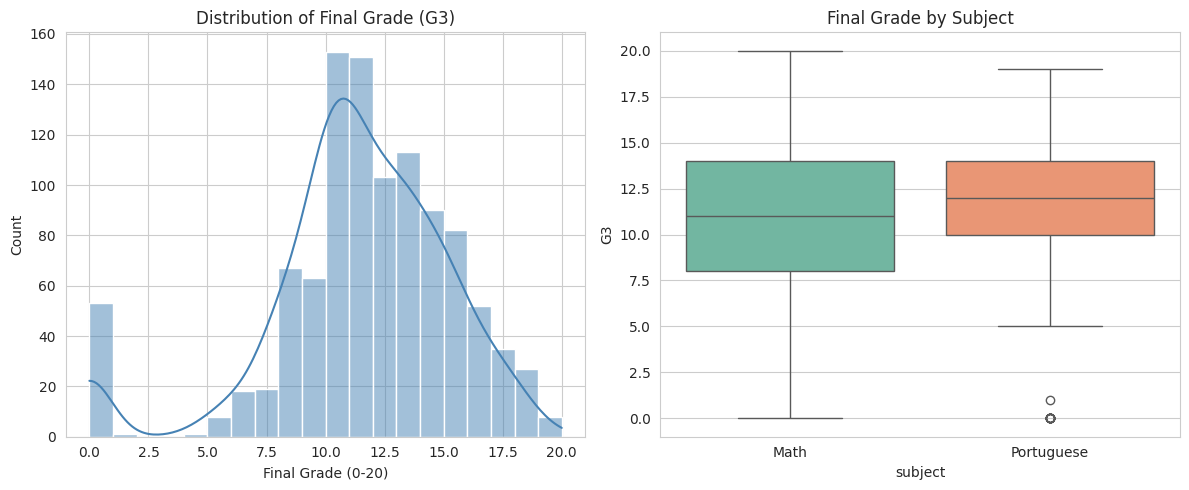

Mean G3: 11.34
Median G3: 11.00
Pass rate (G3 >= 10): 78.0%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['G3'], bins=20, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Final Grade (G3)')
axes[0].set_xlabel('Final Grade (0-20)')

sns.boxplot(x='subject', y='G3', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Final Grade by Subject')

plt.tight_layout()
plt.show()

print(f"Mean G3: {df['G3'].mean():.2f}")
print(f"Median G3: {df['G3'].median():.2f}")
print(f"Pass rate (G3 >= 10): {(df['G3'] >= 10).mean():.1%}")

## 3. Study Habits and Academic Performance

/tmp/ipykernel_498/2904338688.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='studytime', y='G3', data=df, ax=axes[0], palette='Blues')


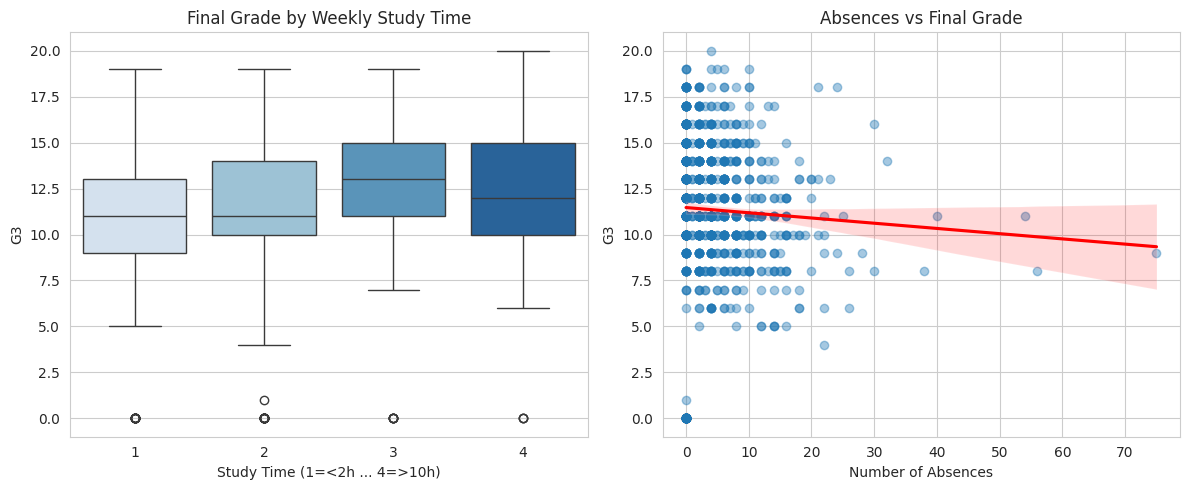

Correlation studytime ~ G3: 0.162
Correlation absences ~ G3: -0.046


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(x='studytime', y='G3', data=df, ax=axes[0], palette='Blues')
axes[0].set_title('Final Grade by Weekly Study Time')
axes[0].set_xlabel('Study Time (1=<2h ... 4=>10h)')

sns.regplot(x='absences', y='G3', data=df, ax=axes[1], scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
axes[1].set_title('Absences vs Final Grade')
axes[1].set_xlabel('Number of Absences')

plt.tight_layout()
plt.show()

# Correlation
print(f"Correlation studytime ~ G3: {df['studytime'].corr(df['G3']):.3f}")
print(f"Correlation absences ~ G3: {df['absences'].corr(df['G3']):.3f}")

In [8]:
# Group statistics
print("Mean Final Grade by Study Time:")
print(df.groupby('studytime')['G3'].agg(['mean', 'std', 'count']).round(2))

print("\nMean Final Grade by Failures:")
print(df.groupby('failures')['G3'].agg(['mean', 'count']).round(2))

Mean Final Grade by Study Time:
            mean   std  count
studytime                    
1          10.58  3.89    317
2          11.34  3.77    503
3          12.49  3.62    162
4          12.27  4.22     62

Mean Final Grade by Failures:
           mean  count
failures              
0         12.05    861
1          8.43    120
2          7.48     33
3          6.80     30


## 4. Demographic and Family Factors

/tmp/ipykernel_498/363989934.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sex', y='G3', data=df, ax=axes[0,0], palette='Set1')
/tmp/ipykernel_498/363989934.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='address', y='G3', data=df, ax=axes[0,1], palette='Set2')
/tmp/ipykernel_498/363989934.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Medu', y='G3', data=df, ax=axes[1,0], palette='Greens')
/tmp/ipykernel_498/363989934.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed 

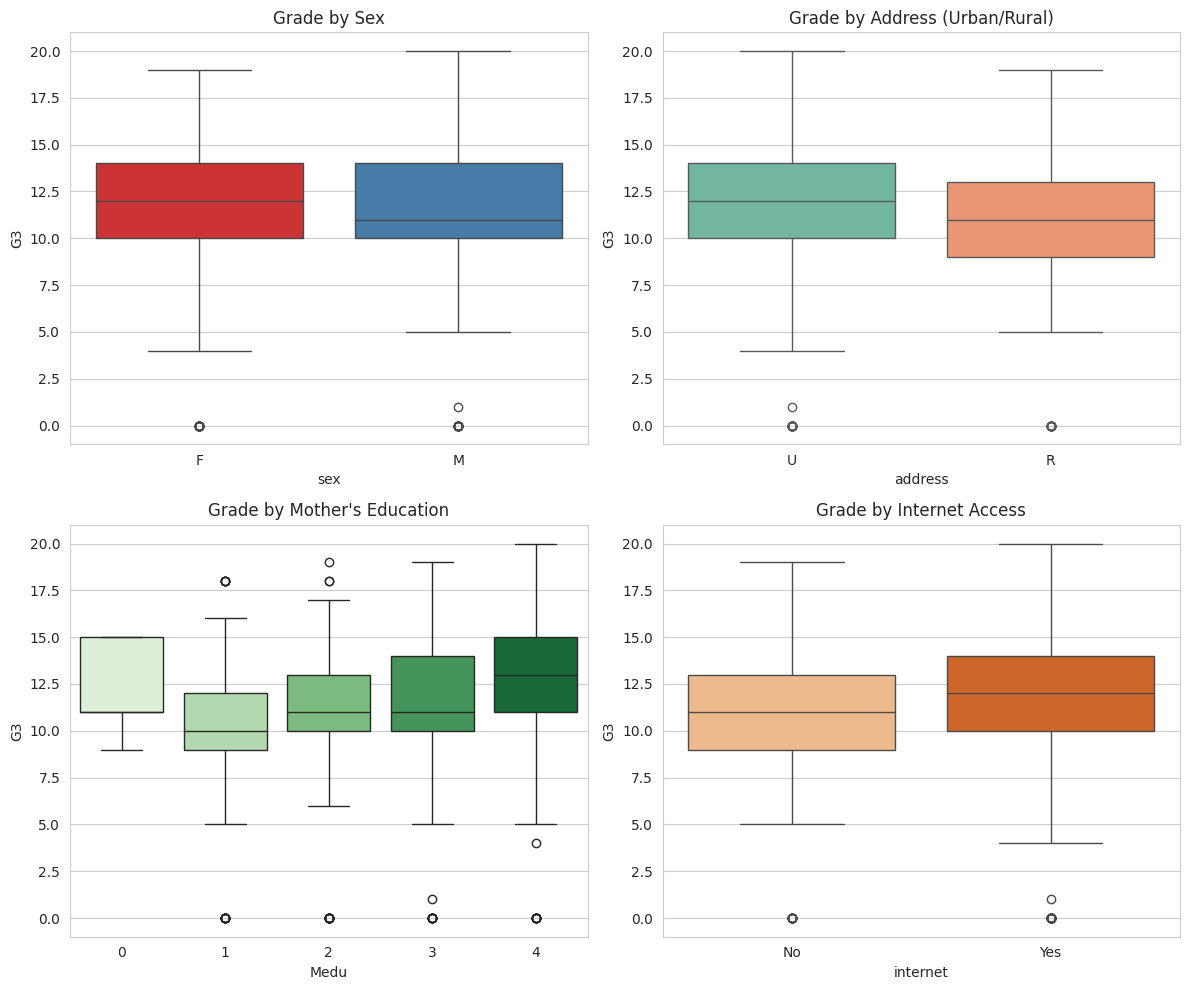

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.boxplot(x='sex', y='G3', data=df, ax=axes[0,0], palette='Set1')
axes[0,0].set_title('Grade by Sex')

sns.boxplot(x='address', y='G3', data=df, ax=axes[0,1], palette='Set2')
axes[0,1].set_title('Grade by Address (Urban/Rural)')

sns.boxplot(x='Medu', y='G3', data=df, ax=axes[1,0], palette='Greens')
axes[1,0].set_title("Grade by Mother's Education")

sns.boxplot(x='internet', y='G3', data=df, ax=axes[1,1], palette='Oranges')
axes[1,1].set_title('Grade by Internet Access')
axes[1,1].set_xticklabels(['No', 'Yes'])

plt.tight_layout()
plt.show()

## 5. Correlation Analysis

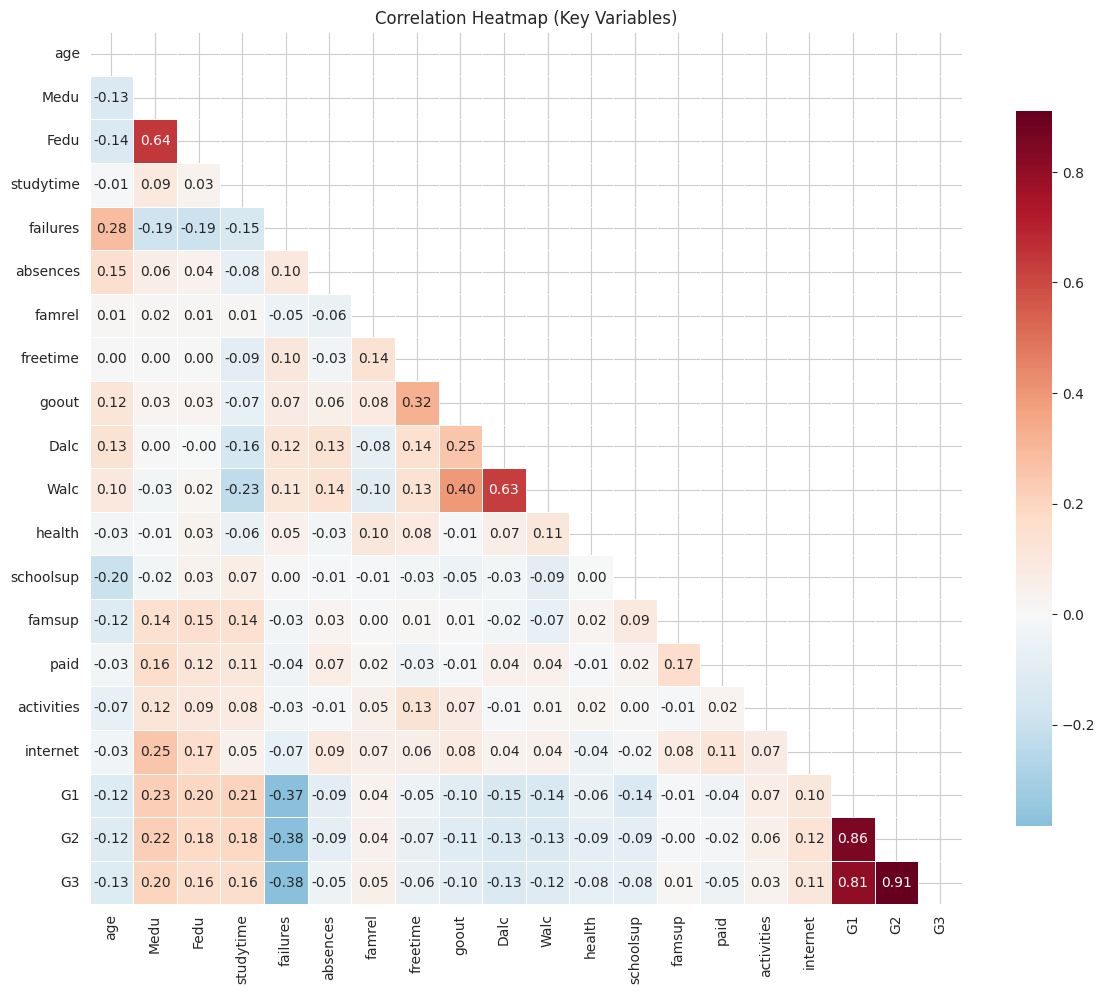

In [10]:
# Select numeric columns of interest
numeric_cols = ['age', 'Medu', 'Fedu', 'studytime', 'failures', 'absences',
                'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health',
                'schoolsup', 'famsup', 'paid', 'activities', 'internet', 'G1', 'G2', 'G3']

corr = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": .8})
plt.title('Correlation Heatmap (Key Variables)')
plt.tight_layout()
plt.show()

In [11]:
# Top correlations with G3
g3_corr = corr['G3'].drop('G3').sort_values(key=abs, ascending=False)
print("Strongest correlations with Final Grade (G3):")
print(g3_corr.head(10).round(3))

Strongest correlations with Final Grade (G3):
G2           0.911
G1           0.809
failures    -0.383
Medu         0.201
studytime    0.162
Fedu         0.160
Dalc        -0.130
age         -0.125
Walc        -0.116
internet     0.107
Name: G3, dtype: float64


## 6. Key Insights Summary

- **Past grades (G1, G2)** are the strongest predictors of final grade (as expected).
- **Failures** show strong negative correlation with performance.
- **Study time** has a positive but moderate relationship with grades.
- **Absences** negatively correlate with grades.
- **Mother's education (Medu)** and wanting higher education are positive factors.
- Alcohol consumption (especially weekend) shows negative association.

These findings can guide feature selection for predictive modeling in the next phase.

In [12]:
# Optional: Export key summary table
summary = df.groupby(['subject', 'studytime']).agg(
    mean_grade=('G3', 'mean'),
    median_grade=('G3', 'median'),
    count=('G3', 'count'),
    mean_absences=('absences', 'mean')
).round(2).reset_index()
print(summary)
summary.to_csv('eda_summary_by_studytime.csv', index=False)

      subject  studytime  mean_grade  median_grade  count  mean_absences
0        Math          1       10.05          10.0    105           5.76
1        Math          2       10.17          11.0    198           6.28
2        Math          3       11.40          12.0     65           4.54
3        Math          4       11.26          12.0     27           4.15
4  Portuguese          1       10.84          11.0    212           4.34
5  Portuguese          2       12.09          12.0    305           3.60
6  Portuguese          3       13.23          13.0     97           2.62
7  Portuguese          4       13.06          13.0     35           2.94
